In [7]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [8]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

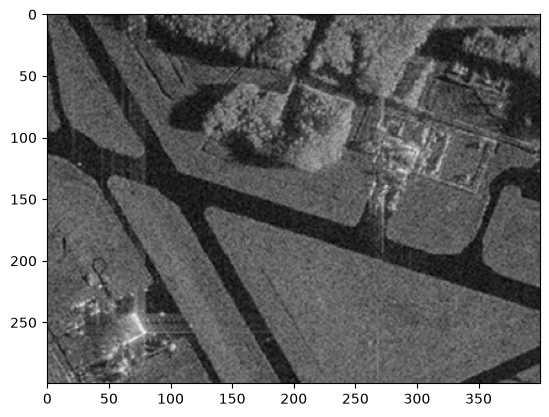

In [9]:
plt.imshow(image_gray, cmap="gray")

In [10]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])

    if abs(av_val - img[point]) <= T:
        return True

    return False

In [11]:
def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask

    return mask*255

# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.

In [12]:
seed_point = (250,250)
mask = region_growing(image_gray,seed_point,homo_average,2, 18)

15
30
47
69
79
103
119
130
144
169
188
205
224
235
244
271
307
301
320
347
358
409
396
345
280
284
288
295
306
312
318
325
328
327
331
340
316
325
327
323
319
323
315
310
302
299
292
292
285
281
266
272
263
268
258
251
240
239
233
216
214
311
202
201
200
195
190
175
172
165
162
153
146
118
83
80
79
79
74
75
71
67
65
63
61
59
58
58
57
57
54
47
47
50
50
47
45
44
39
39
39
35
34
30
32
32
28
30
28
28
27
24
22
21
20
16
14
13
10
8
8
2
0


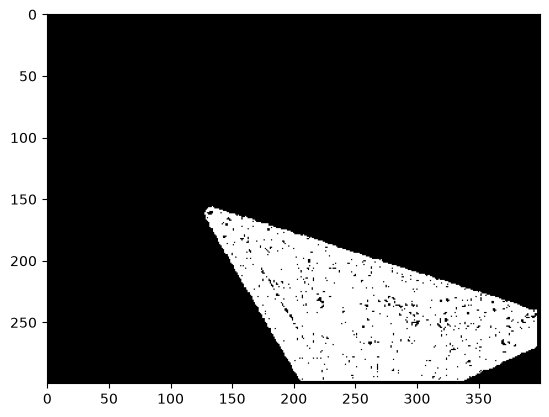

In [13]:
plt.imshow(mask, cmap="gray")

# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.

In [14]:
def homo_median(img, mask, point, T):
    med_val = np.median(img[mask > 0])

    if abs(med_val - img[point]) <= T:
        return True

    return False
seed_point = (250, 250)
mask_median = region_growing(image_gray, seed_point, homo_median, 2, 18)

15
30
47
69
81
103
120
130
144
170
190
205
225
247
248
272
290
302
322
375
361
381
398
345
280
284
290
296
307
312
320
325
328
330
332
342
373
326
329
326
322
323
317
310
308
303
291
296
288
283
271
273
265
268
258
252
242
241
235
217
215
212
203
204
200
195
190
175
171
165
163
153
147
118
83
80
79
79
74
75
71
67
64
64
60
60
58
56
57
56
52
47
47
50
50
47
45
44
39
39
39
35
34
30
32
32
28
30
28
28
27
24
22
21
20
16
14
13
10
8
8
2
0


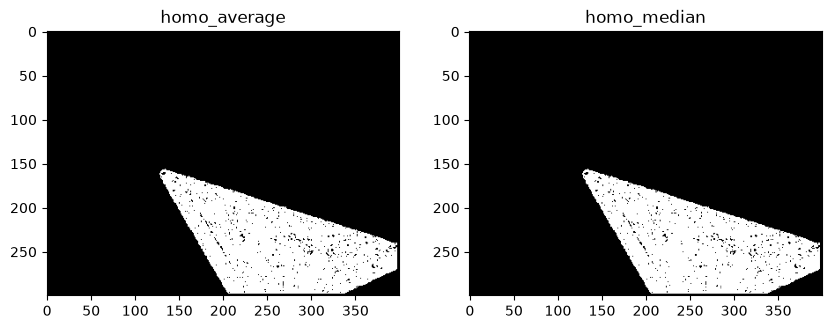

In [15]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("homo_average")
plt.imshow(mask, cmap="gray")

plt.subplot(1, 2, 2)
plt.title("homo_median")
plt.imshow(mask_median, cmap="gray")

Вывод: результат примерно одинаковый 

# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

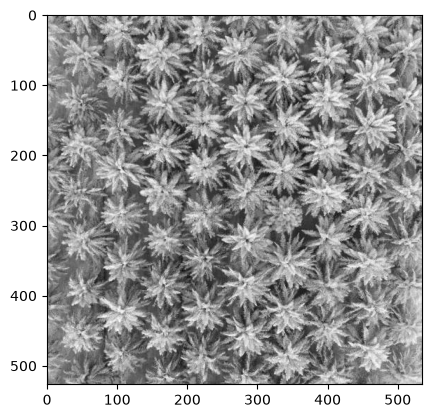

In [87]:
image = cv2.imread('palm_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")

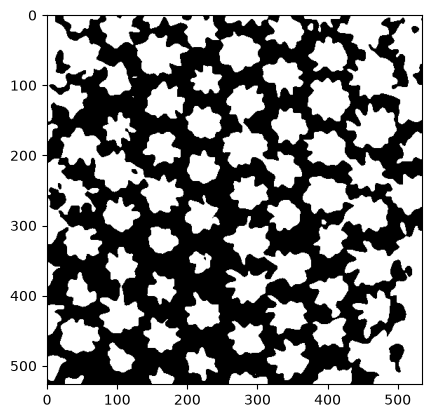

In [88]:
blur = cv2.GaussianBlur(image_gray, (21, 21), 0)#cv2.medianBlur(image_gray, 3)
ret, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
plt.imshow(thresh, cmap="gray")

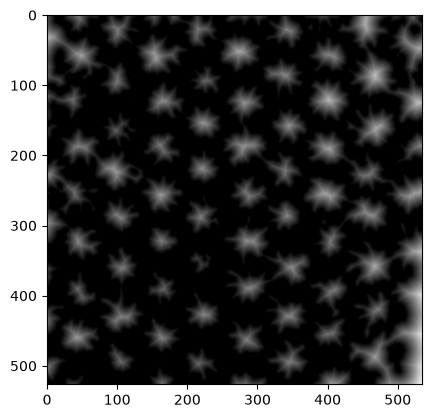

In [89]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)
plt.imshow(dist, cmap="gray")

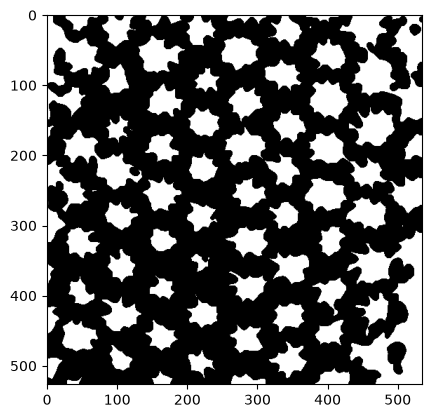

In [90]:
ret, sure_fg = cv2.threshold(dist, 0.1 * dist.max(), 255, cv2.THRESH_BINARY)
plt.imshow(sure_fg, cmap="gray")

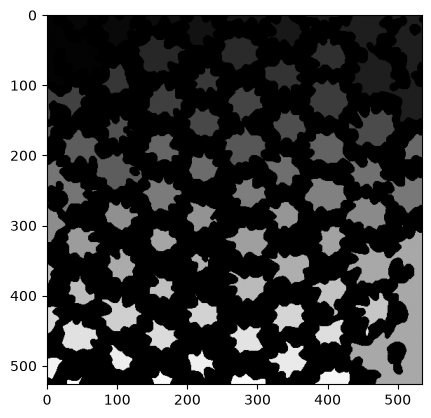

In [91]:
sure_fg = sure_fg.astype(np.uint8)
ret, markers = cv2.connectedComponents(sure_fg)
plt.imshow(markers, cmap="gray")

In [92]:
markers = cv2.watershed(image, markers)

Количество пальмовых деревьев: 85


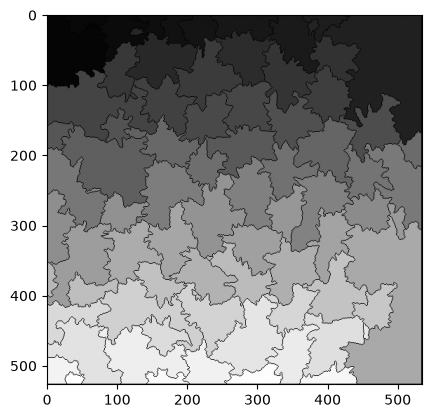

In [93]:
plt.imshow(markers, cmap="gray")
print("Количество пальмовых деревьев:", ret - 1)